In [1]:
import pandas as pd, glob
df = pd.concat([pd.read_csv(f, encoding="latin-1", on_bad_lines="skip") for f in glob.glob("data/*.csv")])
df.head()

,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA
0,E0,13/08/16,Burnley,Swansea,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,13/08/16,Crystal Palace,West Brom,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,13/08/16,Everton,Tottenham,1,1,D,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,13/08/16,Hull,Leicester,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,13/08/16,Man City,Sunderland,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [2]:
df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
df = df.sort_values("Date").reset_index(drop=True)
df.head()

C:\Users\MY PC\AppData\Local\Temp\ipykernel_13764\2831496088.py:1: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)


,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,BMGMCA,BVCH,BVCD,BVCA,CLCH,CLCD,CLCA,LBCH,LBCD,LBCA
0,E0,2016-08-13,Burnley,Swansea,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,E0,2016-08-13,Crystal Palace,West Brom,0,1,A,0,0,D,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,E0,2016-08-13,Everton,Tottenham,1,1,D,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,E0,2016-08-13,Hull,Leicester,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,E0,2016-08-13,Man City,Sunderland,2,1,H,1,0,H,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
def elo_expected(r_home, r_away, home_adv=60):
    return 1/(1+10**((r_away - (r_home + home_adv))/400))

In [4]:
ratings, home_elo, away_elo = {}, [], []
K = 20
for _, row in df.iterrows():
    h, a = row["HomeTeam"], row["AwayTeam"]
    rh, ra = ratings.get(h, 1500), ratings.get(a,1500)
    home_elo.append(rh)
    away_elo.append(ra)
    actual = {"H": 1, "D": 0.5, "A": 0}.get(row["FTR"])
    if actual is None:
        continue
    change = K * (actual - elo_expected(rh, ra))
    ratings[h], ratings[a] = rh + change, ra - change
df["home_elo"], df["away_elo"] = home_elo, away_elo

C:\Users\MY PC\AppData\Local\Temp\ipykernel_13764\1475025330.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df["home_elo"], df["away_elo"] = home_elo, away_elo


In [5]:
sorted(ratings.items(), key=lambda x: x[1], reverse=True)[:6]

[('Arsenal', 1775.1101525112842),
 ('Man City', 1754.7550601301489),
 ('Liverpool', 1665.7506510158585),
 ('Man United', 1658.728579713061),
 ('Aston Villa', 1647.1010077677056),
 ('Bournemouth', 1624.4999400594406)]

In [6]:
home = pd.DataFrame({"Date": df["Date"], "Team": df["HomeTeam"], "GF": df["FTHG"], "GA": df["FTAG"], "Shots": df["HS"], "Result": df["FTR"].map({"H": 3, "D": 1, "A": 0})})
away = pd.DataFrame({"Date": df["Date"], "Team": df["AwayTeam"], "GF": df["FTAG"], "GA": df["FTHG"], "Shots": df["AS"], "Result": df["FTR"].map({"A": 3, "D": 1, "H": 0})})
teams = pd.concat([home, away]).sort_values("Date").reset_index(drop=True)
teams.head()

,Date,Team,GF,GA,Shots,Result
0,2016-08-13,Burnley,0,1,10,0
1,2016-08-13,Tottenham,1,1,13,1
2,2016-08-13,Leicester,1,2,18,0
3,2016-08-13,Sunderland,1,2,7,0
4,2016-08-13,Stoke,1,1,12,1


In [7]:
for col in ["GF", "GA", "Shots", "Result"]:
    teams[col + "_last5"] = teams.groupby("Team")[col].transform(lambda s: s.shift(1).rolling(5).mean())
teams.head(10)

,Date,Team,GF,GA,Shots,Result,GF_last5,GA_last5,Shots_last5,Result_last5
0,2016-08-13,Burnley,0,1,10,0,NaN,NaN,NaN,NaN
1,2016-08-13,Tottenham,1,1,13,1,NaN,NaN,NaN,NaN
2,2016-08-13,Leicester,1,2,18,0,NaN,NaN,NaN,NaN
3,2016-08-13,Sunderland,1,2,7,0,NaN,NaN,NaN,NaN
4,2016-08-13,Stoke,1,1,12,1,NaN,NaN,NaN,NaN
5,2016-08-13,Watford,1,1,5,1,NaN,NaN,NaN,NaN
6,2016-08-13,West Brom,1,0,13,3,NaN,NaN,NaN,NaN
7,2016-08-13,Swansea,1,0,17,3,NaN,NaN,NaN,NaN
8,2016-08-13,Southampton,1,1,24,1,NaN,NaN,NaN,NaN
9,2016-08-13,Middlesbrough,1,1,12,1,NaN,NaN,NaN,NaN


In [8]:
teams[teams["Team"] == "Arsenal"].tail(10)

,Date,Team,GF,GA,Shots,Result,GF_last5,GA_last5,Shots_last5,Result_last5
7396,2026-03-01,Arsenal,2,1,12,3,2.8,0.8,13.4,2.2
7419,2026-03-04,Arsenal,1,0,7,3,2.4,1.0,13.0,2.2
7429,2026-03-14,Arsenal,2,0,25,3,2.0,1.0,11.2,2.2
7467,2026-04-11,Arsenal,1,2,15,0,2.2,0.8,14.8,2.6
7494,2026-04-19,Arsenal,1,2,9,0,2.0,0.8,15.8,2.4
7513,2026-04-25,Arsenal,1,0,11,3,1.4,1.0,13.6,1.8
7527,2026-05-02,Arsenal,3,0,18,3,1.2,0.8,13.4,1.8
7554,2026-05-10,Arsenal,1,0,15,3,1.6,0.8,15.6,1.8
7575,2026-05-18,Arsenal,1,0,13,3,1.4,0.8,13.6,1.8
7584,2026-05-24,Arsenal,2,1,17,3,1.4,0.4,13.2,2.4


In [9]:
features = ["GF_last5", "GA_last5", "Shots_last5", "Result_last5"]
home_form = teams[["Date", "Team"] + features].rename(columns={f: "home_" + f for f in features})
away_form = teams[["Date", "Team"] + features].rename(columns={f: "away_" + f for f in features})
matches = df[["Date", "HomeTeam", "AwayTeam", "FTR", "home_elo", "away_elo"]]
matches = matches.merge(home_form, left_on=["Date", "HomeTeam"], right_on=["Date", "Team"]).drop(columns="Team")
matches = matches.merge(away_form, left_on=["Date", "AwayTeam"], right_on=["Date", "Team"]).drop(columns="Team")
matches = matches.dropna()
matches.head()

,Date,HomeTeam,AwayTeam,FTR,home_elo,away_elo,home_GF_last5,home_GA_last5,home_Shots_last5,home_Result_last5,away_GF_last5,away_GA_last5,away_Shots_last5,away_Result_last5
50,2016-09-24,Swansea,Man City,A,1482.072450,1546.337900,0.8,1.4,10.8,0.8,3.0,0.8,17.6,3.0
51,2016-09-24,Stoke,West Brom,D,1463.713446,1497.481632,0.6,2.8,10.8,0.2,1.2,1.0,11.4,1.4
52,2016-09-24,Middlesbrough,Tottenham,A,1491.174360,1525.730530,1.0,1.4,9.2,1.0,1.6,0.4,19.0,2.2
53,2016-09-24,Sunderland,Crystal Palace,A,1464.477890,1499.000753,0.6,1.8,9.4,0.2,1.4,1.0,14.8,1.4
54,2016-09-24,Liverpool,Hull,H,1524.914414,1497.847553,2.2,1.6,17.0,2.0,1.2,1.4,10.2,1.4


In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

X_cols = [c for c in matches.columns if c.startswith(("home_", "away_"))]
train = matches[matches["Date"] < "2025-08-01"]
test = matches[matches["Date"] >= "2025-08-01"]
X_train, y_train = train[X_cols], train["FTR"]
X_test, y_test = test[X_cols], test["FTR"]

In [22]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(X_train, y_train)
pred = model.predict(X_test)
print("Model accuracy:", accuracy_score(y_test, pred))
print("Always-home baseline:", (y_test == "H").mean())

Model accuracy: 0.48947368421052634
Always-home baseline: 0.4263157894736842


In [12]:
rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42)
rf.fit(X_train, y_train)
print("Random forest accuracy:", accuracy_score(y_test, rf.predict(X_test)))

Random forest accuracy: 0.4789473684210526


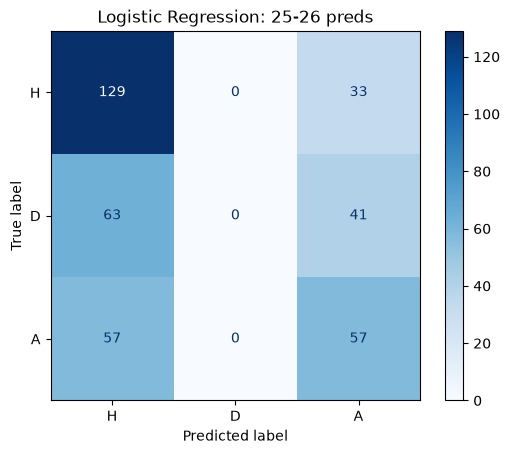

In [23]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["H", "D", "A"]
cm = confusion_matrix(y_test, pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap="Blues")
plt.title("Logistic Regression: 25-26 preds")
plt.show()

In [24]:
fit_part = train[train["Date"] < "2024-08-01"]
val = train[train["Date"] >= "2024-08-01"]
tmp = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
tmp.fit(fit_part[X_cols], fit_part["FTR"])
val_probs = pd.DataFrame(tmp.predict_proba(val[X_cols]), columns=tmp.classes_, index=val.index)
for m in [0, 0.05, 0.10, 0.15, 0.20]:
    close = (val_probs["H"] - val_probs["A"]).abs() < m
    picks = val_probs.idxmax(axis=1).where(~close, "D")
    print(m, round(accuracy_score(val["FTR"], picks), 3), (picks == "D").sum(), "draws")

0 0.528 0 draws
0.05 0.509 26 draws
0.1 0.499 58 draws
0.15 0.485 90 draws
0.2 0.477 120 draws


The model wasn't predicting any draws. I tested calling a draw when the two teams' win probability was withn a margin. everything above 0 reduced accuracy and the draw calls were very few to the point of being redundant. this made me keep best_m as 0.

In [28]:
best_m = 0.0
test_probs = pd.DataFrame(model.predict_proba(X_test), columns=model.classes_, index=X_test.index)
close = (test_probs["H"] - test_probs["A"]).abs() < best_m
final_picks = test_probs.idxmax(axis=1).where(~close, "D")
print("Accuracy with draw rule:", accuracy_score(y_test, final_picks))
print("Draws predicted:", (final_picks == "D").sum())

Accuracy with draw rule: 0.48947368421052634
Draws predicted: 0


In [29]:
results = test[["Date", "HomeTeam", "AwayTeam", "FTR"]].copy()
results["Pick"] = final_picks
results[["P(H)", "P(D)", "P(A)"]] = test_probs[["H", "D", "A"]].round(2)
results.tail(10)

,Date,HomeTeam,AwayTeam,FTR,Pick,P(H),P(D),P(A)
3790,2026-05-24,Nott'm Forest,Bournemouth,D,A,0.37,0.26,0.37
3791,2026-05-24,Man City,Aston Villa,A,H,0.76,0.15,0.09
3792,2026-05-24,Sunderland,Chelsea,H,A,0.33,0.25,0.42
3793,2026-05-24,Liverpool,Brentford,D,H,0.60,0.22,0.18
3794,2026-05-24,Tottenham,Everton,H,A,0.35,0.23,0.42
3795,2026-05-24,Crystal Palace,Arsenal,A,A,0.23,0.23,0.53
3796,2026-05-24,Burnley,Wolves,D,A,0.33,0.26,0.41
3797,2026-05-24,Brighton,Man United,A,H,0.46,0.25,0.29
3798,2026-05-24,Fulham,Newcastle,H,H,0.39,0.24,0.37
3799,2026-05-24,West Ham,Leeds,H,H,0.37,0.27,0.36


In [30]:
draw_calls = final_picks == "D"
print("Draw calls:", draw_calls.sum())
print("Correct draw calls:", (y_test[draw_calls] == "D").sum())

Draw calls: 0
Correct draw calls: 0
